# 04 – Luật kết hợp: trong cửa hàng và đồng vị trí (co-location)

| Phần | Transaction | Item | Câu hỏi |
|---|---|---|---|
| (a) Trong cửa hàng | 1 cửa hàng | 20 nhãn productType | Quán bán X thường bán kèm Y? |
| (b1) Lưới | 1 ô 150/200/300 m | 10 nhóm loại hình có mặt trong ô | Khu có X thường có Y? |
| (b2) Lân cận (trọng tâm) | 1 cửa hàng + bán kính R | `self:<loại của nó>`, `near:<loại trong R>` | Quán Y hay mở gần những loại nào? |

**Độ đo:**
- support = P(A ∪ B); confidence = P(B | A);
- lift = P(B | A) / P(B): **> 1** nghĩa là A và B xuất hiện cùng nhau nhiều hơn ngẫu nhiên;
- conviction = (1 − P(B)) / (1 − conf), càng lớn thì luật càng "ít sai" so với giả định độc lập;
- leverage = P(A ∪ B) − P(A)·P(B).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from src import cleaning as cl, geo, features as ft, viz

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
viz.set_style()
PROC = ROOT / "data" / "processed"
TABLES = viz.TABLE_DIR

from src import assoc

df = pd.read_csv(PROC / "stores_clean.csv")
df["type_group"] = [ft.primary_group(t, c) for t, c in zip(df["product_types"], df["category"])]
print(df.shape)

def show(r, n=15, cols=("antecedents_str", "consequents_str", "support", "support_count", "confidence", "lift", "conviction")):
    return r.head(n)[list(cols)].round(3)

(3208, 48)


## (a) Luật trong cửa hàng: Apriori và FP-Growth

In [2]:
T_store = df["product_types"].str.split("|").tolist()
oh_store = assoc.encode(T_store)
print(f"{len(T_store)} transaction, {oh_store.shape[1]} item, trung bình {np.mean([len(t) for t in T_store]):.2f} item/transaction, "
      f"{np.mean([len(t) > 1 for t in T_store]):.1%} transaction có ≥ 2 item")
print("Support từng item:", oh_store.mean().sort_values(ascending=False).round(3).head(10).to_dict())

3208 transaction, 20 item, trung bình 1.25 item/transaction, 18.4% transaction có ≥ 2 item
Support từng item: {'Coffee - Tea - Juice': 0.232, 'Noodles & Congee': 0.211, 'Rice': 0.12, 'Snack': 0.111, 'Hotpot & Grill': 0.094, 'Others': 0.088, 'Milk Tea': 0.083, 'Bread': 0.08, 'International Food': 0.051, 'Dessert': 0.05}


In [3]:
timing = []
for name, oh in [("Trong cửa hàng (20 item)", oh_store)]:
    t = assoc.time_algorithms(oh, supports=(0.002, 0.005, 0.01, 0.02), repeats=5); t["dataset"] = name; timing.append(t)
timing_store = pd.concat(timing)
timing_store.pivot(index="min_support", columns="algorithm", values=["time_ms", "n_itemsets"]).round(1)

time_ms           n_itemsets          
algorithm   Apriori FP-Growth    Apriori FP-Growth
min_support                                       
0.002           3.7      15.2       72.0      72.0
0.005           2.4      11.0       36.0      36.0
0.010           2.3      11.0       24.0      24.0
0.020           3.2      14.9       15.0      15.0

**Chọn ngưỡng:** chỉ khoảng 18% cửa hàng có từ 2 nhãn trở lên, nên tập phổ biến nhiều phần tử rất hiếm.
- Chọn **min_support = 0,005**, tương đương ≥ 16 cửa hàng. Đây là mức tối thiểu để một tổ hợp được coi là "mẫu" thay vì trùng hợp.
- Chọn **min_confidence = 0,3** và lift > 1.

In [4]:
rules_store = assoc.mine_rules(oh_store, min_support=0.005, min_confidence=0.3)
rules_store.drop(columns=["antecedents", "consequents"]).to_csv(TABLES / "04_rules_in_store.csv", index=False, encoding="utf-8-sig")
print(f"Số luật: {len(rules_store)}")
show(rules_store)

Số luật: 4


,antecedents_str,consequents_str,support,support_count,confidence,lift,conviction
0,Fast Food,International Food,0.008,26,0.317,6.165,1.389
1,Noodles & Congee + Rice,Hotpot & Grill,0.011,34,0.507,5.426,1.840
2,Hotpot & Grill + Noodles & Congee,Rice,0.011,34,0.576,4.802,2.077
3,Hotpot & Grill + Rice,Noodles & Congee,0.011,34,0.810,3.842,4.144


## (b1) Co-location theo lưới ô vuông

Mỗi ô lưới (trong hệ UTM, đơn vị mét) là một transaction, gồm tập các nhóm loại hình có mặt trong ô.
Chỉ giữ các ô có ≥ 2 cửa hàng, vì ô chỉ có 1 cửa hàng không thể chứa quan hệ đồng vị trí.

In [5]:
grid_summary, grid_data = [], {}
for size in (150, 200, 300):
    T, info = assoc.grid_transactions(df, size)
    oh = assoc.encode(T)
    grid_data[size] = (T, info, oh)
    r = assoc.mine_rules(oh, min_support=0.1, min_confidence=0.7, min_lift=1.0, max_len=3)
    r = r[r["consequents"].map(len) == 1]
    grid_summary.append(dict(cell_m=size, n_cells=len(T), avg_items=np.mean([len(t) for t in T]),
                             support_cafe=oh["Cà phê & nước"].mean(), min_item_support=oh.mean().min(),
                             n_rules=len(r), median_lift=r["lift"].median() if len(r) else np.nan,
                             max_lift=r["lift"].max() if len(r) else np.nan))
grid_summary = pd.DataFrame(grid_summary)
grid_summary.round(3)

,cell_m,n_cells,avg_items,support_cafe,min_item_support,n_rules,median_lift,max_lift
0,150,357,4.423,0.706,0.171,105,1.181,1.774
1,200,242,5.360,0.798,0.240,191,1.179,1.681
2,300,137,6.190,0.781,0.380,321,1.239,1.583


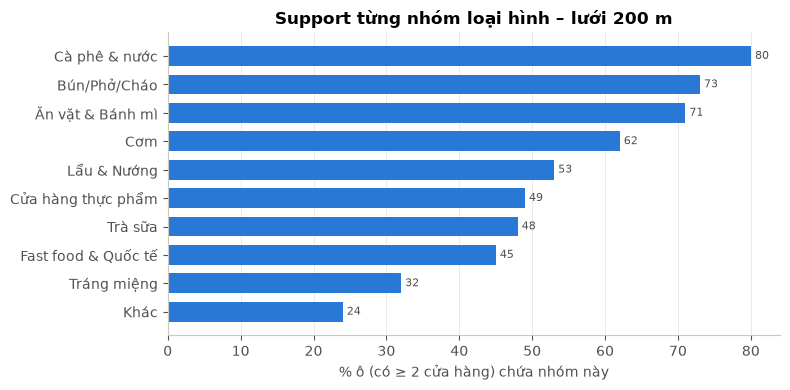

In [6]:
T200, info200, oh200 = grid_data[200]
item_sup = oh200.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
viz.barh_counts((item_sup * 100).round(0), "Support từng nhóm loại hình – lưới 200 m",
                "% ô (có ≥ 2 cửa hàng) chứa nhóm này", ax=ax)
fig.tight_layout(); viz.save_fig(fig, "04_grid200_item_support"); plt.show()

**Chọn tham số cho lưới 200 m:**
- Mọi nhóm loại hình đều xuất hiện ở 24–80% số ô. Vì vậy chọn **min_support = 0,10** (≥ 24 ô): đủ thấp để giữ cả nhóm hiếm như Tráng miệng (32%), nhưng loại được các tổ hợp chỉ xuất hiện ở vài ô.
- Chọn **min_confidence = 0,7**: do item nền đã rất phổ biến (cà phê có mặt ở 80% số ô), nếu đặt confidence thấp sẽ giữ lại vô số luật hiển nhiên.
- Giới hạn **max_len = 3**, tức tối đa 2 vế trái và 1 vế phải, để luật dễ diễn giải.
- Giữ **lift > 1**, sau đó xếp hạng theo lift rồi đến conviction.

In [7]:
rules_grid = assoc.mine_rules(oh200, min_support=0.10, min_confidence=0.7, min_lift=1.0, max_len=3)
rules_grid = rules_grid[rules_grid["consequents"].map(len) == 1].reset_index(drop=True)
rules_grid.drop(columns=["antecedents", "consequents"]).to_csv(TABLES / "04_rules_grid200.csv", index=False, encoding="utf-8-sig")
print(f"Số luật (lưới 200 m): {len(rules_grid)}")
show(rules_grid)

Số luật (lưới 200 m): 191


,antecedents_str,consequents_str,support,support_count,confidence,lift,conviction
0,Trà sữa + Tráng miệng,Fast food & Quốc tế,0.136,33,0.750,1.681,2.215
1,Trà sữa + Tráng miệng,Cửa hàng thực phẩm,0.145,35,0.795,1.631,2.505
2,Fast food & Quốc tế + Tráng miệng,Lẩu & Nướng,0.153,37,0.860,1.627,3.376
3,Fast food & Quốc tế + Tráng miệng,Trà sữa,0.136,33,0.767,1.615,2.257
4,Cơm + Tráng miệng,Cửa hàng thực phẩm,0.174,42,0.778,1.595,2.306
5,Lẩu & Nướng + Tráng miệng,Fast food & Quốc tế,0.153,37,0.712,1.594,1.920
6,Lẩu & Nướng + Trà sữa,Fast food & Quốc tế,0.190,46,0.708,1.586,1.894
7,Lẩu & Nướng + Tráng miệng,Cửa hàng thực phẩm,0.165,40,0.769,1.578,2.220
8,Fast food & Quốc tế + Tráng miệng,Cửa hàng thực phẩm,0.136,33,0.767,1.574,2.203
9,Tráng miệng + Ăn vặt & Bánh mì,Cửa hàng thực phẩm,0.190,46,0.754,1.547,2.084


**Cảnh báo: luật lưới bị nhiễu bởi mật độ.** Ô càng đông cửa hàng thì càng có nhiều loại hình. Vì vậy một luật "A + B → C" có lift cao có thể chỉ phản ánh rằng *ô chứa A và B là ô đông quán*, chứ chưa chắc A, B, C thực sự "hút" nhau. Kiểm tra:

In [8]:
n_st = info200["n_stores"].to_numpy()
chk = []
for _, r in rules_grid.head(10).iterrows():
    mask = oh200[list(r["antecedents"])].all(axis=1).to_numpy()
    chk.append(dict(rule=f"{r['antecedents_str']} → {r['consequents_str']}", lift=r["lift"],
                    stores_per_cell_with_A=n_st[mask].mean(), stores_per_cell_all=n_st.mean()))
chk = pd.DataFrame(chk)
rho = np.corrcoef(n_st, [len(t) for t in T200])[0, 1]
print(f"Tương quan (Pearson) giữa số cửa hàng trong ô và số nhóm loại hình trong ô: r = {rho:.2f}")
chk.round(2)

Tương quan (Pearson) giữa số cửa hàng trong ô và số nhóm loại hình trong ô: r = 0.82


,rule,lift,stores_per_cell_with_A,stores_per_cell_all
0,Trà sữa + Tráng miệng → Fast food & Quốc tế,1.68,26.07,12.99
1,Trà sữa + Tráng miệng → Cửa hàng thực phẩm,1.63,26.07,12.99
2,Fast food & Quốc tế + Tráng miệng → Lẩu & Nướng,1.63,27.42,12.99
3,Fast food & Quốc tế + Tráng miệng → Trà sữa,1.61,27.42,12.99
4,Cơm + Tráng miệng → Cửa hàng thực phẩm,1.60,23.85,12.99
5,Lẩu & Nướng + Tráng miệng → Fast food & Quốc tế,1.59,25.83,12.99
6,Lẩu & Nướng + Trà sữa → Fast food & Quốc tế,1.59,23.71,12.99
7,Lẩu & Nướng + Tráng miệng → Cửa hàng thực phẩm,1.58,25.83,12.99
8,Fast food & Quốc tế + Tráng miệng → Cửa hàng thực phẩm,1.57,27.42,12.99
9,Tráng miệng + Ăn vặt & Bánh mì → Cửa hàng thực phẩm,1.55,22.46,12.99


Các ô chứa vế trái của luật lưới đông gấp khoảng 2–3 lần ô trung bình, và số cửa hàng trong ô tương quan rất mạnh với số loại hình. Vì vậy **luật lưới chủ yếu mô tả "khu đông quán"**.
Ta dùng phương pháp **lân cận lấy cửa hàng làm tâm** dưới đây làm kết quả chính, vì ở đó vế phải là loại hình của *một cửa hàng cụ thể*, nên không phụ thuộc trực tiếp vào số cửa hàng trong vùng.

## (b2) Co-location theo lân cận (trọng tâm)

Mỗi cửa hàng là một transaction gồm:
- `self:<nhóm của nó>`
- `near:<nhóm>` cho mỗi nhóm có ít nhất một cửa hàng trong bán kính R (không tính chính nó).

Ta chỉ giữ các luật có dạng **`near:… → self:Y`**, đọc là *"ở vị trí xung quanh có các loại …, loại Y xuất hiện nhiều hơn mức bình thường lift lần"*.
Đây đúng là câu hỏi của bài toán gợi ý loại hình theo vị trí.

**Chọn R = 100 m**, cùng thang đo với eps của DBSCAN (notebook 03). Đây là bán kính khoảng 1–2 phút đi bộ, tức phạm vi khách hàng nhìn thấy các quán xung quanh. R = 50 m được dùng để so sánh.

In [9]:
T_nb = {R: assoc.neighborhood_transactions(df, R) for R in (50, 100)}
oh_nb = {R: assoc.encode(T) for R, T in T_nb.items()}
sup = pd.DataFrame({f"R={R} m": oh.mean() for R, oh in oh_nb.items()}).round(3)
sup.sort_values("R=100 m", ascending=False)

,R=50 m,R=100 m
near:Cà phê & nước,0.615,0.882
near:Bún/Phở/Cháo,0.564,0.837
near:Ăn vặt & Bánh mì,0.498,0.812
near:Cơm,0.417,0.679
near:Lẩu & Nướng,0.312,0.627
near:Trà sữa,0.294,0.596
near:Cửa hàng thực phẩm,0.314,0.593
near:Fast food & Quốc tế,0.295,0.572
near:Tráng miệng,0.183,0.424
near:Khác,0.137,0.346


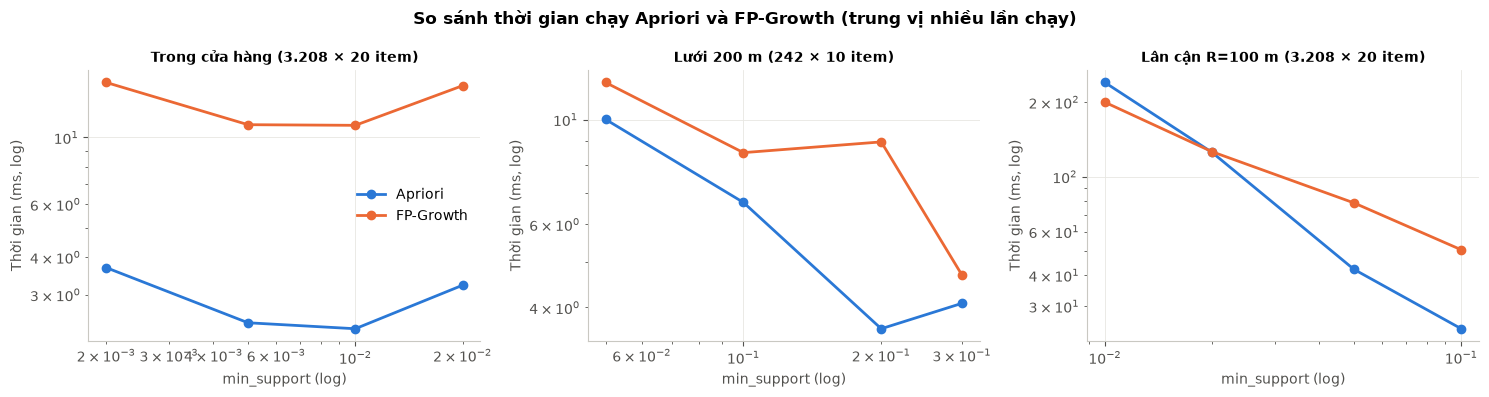

n_itemsets           time_ms          
algorithm                                        Apriori FP-Growth Apriori FP-Growth
dataset                           min_support                                       
Lân cận R=100 m (3.208 × 20 item) 0.010           8157.0    8157.0   239.9     199.6
                                  0.020           5088.0    5088.0   125.2     126.0
                                  0.050           1765.0    1765.0    42.3      78.3
                                  0.100           1028.0    1028.0    24.3      50.7
Lưới 200 m (242 × 10 item)        0.050            885.0     885.0    10.0      12.0
                                  0.100            508.0     508.0     6.7       8.5
                                  0.200            160.0     160.0     3.6       9.0
                                  0.300             58.0      58.0     4.1       4.7
Trong cửa hàng (3.208 × 20 item)  0.002             72.0      72.0     3.7      15.2
                                  0.005             36.0      36.0     2.4      11.0
                                  0.010             24.0      24.0     2.3      11.0
                                  0.020             15.0      15.0     3.2      14.9

In [10]:
t_nb = assoc.time_algorithms(oh_nb[100], supports=(0.01, 0.02, 0.05, 0.1), repeats=3)
t_grid = assoc.time_algorithms(oh200, supports=(0.05, 0.1, 0.2, 0.3), repeats=3)
t_nb["dataset"] = "Lân cận R=100 m (3.208 × 20 item)"; t_grid["dataset"] = "Lưới 200 m (242 × 10 item)"
timing_store["dataset"] = "Trong cửa hàng (3.208 × 20 item)"
timing_all = pd.concat([timing_store, t_grid, t_nb])
timing_all.to_csv(TABLES / "04_apriori_vs_fpgrowth.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, g) in zip(axes, timing_all.groupby("dataset", sort=False)):
    for i, alg in enumerate(["Apriori", "FP-Growth"]):
        gg = g[g["algorithm"] == alg]
        ax.plot(gg["min_support"], gg["time_ms"], "o-", lw=2, ms=6, color=viz.PALETTE[i], label=alg)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(name, fontsize=10); ax.set_xlabel("min_support (log)"); ax.set_ylabel("Thời gian (ms, log)")
axes[0].legend()
fig.suptitle("So sánh thời gian chạy Apriori và FP-Growth (trung vị nhiều lần chạy)", fontweight="bold")
fig.tight_layout(); viz.save_fig(fig, "04_apriori_vs_fpgrowth"); plt.show()
timing_all.pivot_table(index=["dataset", "min_support"], columns="algorithm", values=["time_ms", "n_itemsets"]).round(1)

**Chọn ngưỡng cho luật lân cận:**
- **min_support = 0,01**, tương đương ≥ 32 cửa hàng thỏa cả vế trái và vế phải. Đủ lớn để luật có ý nghĩa thống kê, và vẫn giữ được các nhóm nhỏ như Tráng miệng (3,7% số cửa hàng).
- **Confidence không phù hợp làm ngưỡng chính ở đây**, vì vế phải `self:Y` có xác suất nền thấp (3,7–21%). Một luật có confidence 0,15 vẫn có thể rất mạnh nếu P(Y) = 0,07.
  Vì vậy chỉ đặt min_confidence = 0,05 cho có, và lọc chính bằng **lift ≥ 1,2**, tức Y xuất hiện nhiều hơn ít nhất 20% so với ngẫu nhiên.
- **max_len = 3** (tối đa 2 điều kiện `near:`) để luật dễ diễn giải và tránh bùng nổ tổ hợp.

In [11]:
def nb_rules(R, min_support=0.01, min_lift=1.2):
    r = assoc.mine_rules(oh_nb[R], min_support=min_support, min_confidence=0.05, min_lift=min_lift, max_len=3)
    keep = (r["consequents"].map(len) == 1) & r["consequents_str"].str.startswith("self:") \
           & ~r["antecedents_str"].str.contains("self:")
    return r[keep].reset_index(drop=True)

rules_nb = nb_rules(100)
rules_nb50 = nb_rules(50)
rules_nb.drop(columns=["antecedents", "consequents"]).to_csv(TABLES / "04_rules_neighborhood_R100.csv", index=False, encoding="utf-8-sig")
rules_nb50.drop(columns=["antecedents", "consequents"]).to_csv(TABLES / "04_rules_neighborhood_R50.csv", index=False, encoding="utf-8-sig")
print(f"Số luật near → self (lift ≥ 1,2): R=100 m: {len(rules_nb)} | R=50 m: {len(rules_nb50)}")
print("Số luật theo vế phải (R=100 m):", rules_nb["consequents_str"].value_counts().to_dict())
show(rules_nb, 15)

Số luật near → self (lift ≥ 1,2): R=100 m: 16 | R=50 m: 36
Số luật theo vế phải (R=100 m): {'self:Fast food & Quốc tế': 11, 'self:Tráng miệng': 5}


,antecedents_str,consequents_str,support,support_count,confidence,lift,conviction
0,near:Cửa hàng thực phẩm + near:Khác,self:Tráng miệng,0.014,45,0.056,1.504,1.020
1,near:Fast food & Quốc tế + near:Khác,self:Tráng miệng,0.014,45,0.055,1.465,1.018
2,near:Bún/Phở/Cháo + near:Khác,self:Tráng miệng,0.017,53,0.051,1.366,1.014
3,near:Khác + near:Tráng miệng,self:Tráng miệng,0.011,35,0.051,1.358,1.014
4,near:Cà phê & nước + near:Khác,self:Tráng miệng,0.017,54,0.051,1.354,1.014
5,near:Fast food & Quốc tế + near:Lẩu & Nướng,self:Fast food & Quốc tế,0.039,125,0.091,1.318,1.024
6,near:Cửa hàng thực phẩm + near:Fast food & Quốc tế,self:Fast food & Quốc tế,0.034,110,0.090,1.305,1.023
7,near:Fast food & Quốc tế + near:Tráng miệng,self:Fast food & Quốc tế,0.027,88,0.089,1.293,1.022
8,near:Cà phê & nước + near:Fast food & Quốc tế,self:Fast food & Quốc tế,0.048,153,0.087,1.261,1.020
9,near:Trà sữa + near:Tráng miệng,self:Fast food & Quốc tế,0.026,85,0.087,1.260,1.020


In [12]:
# Luật "hiển nhiên": vế phải là near:Cà phê & nước (có mặt quanh ~88% cửa hàng) -> confidence rất cao nhưng lift ≈ 1
obvious = assoc.mine_rules(oh_nb[100], min_support=0.05, min_confidence=0.8, min_lift=0.0, max_len=2)
obvious = obvious[obvious["consequents_str"] == "near:Cà phê & nước"]
print(f"Luật X → near:Cà phê & nước có confidence ≥ 0,8: {len(obvious)}; lift trong khoảng "
      f"{obvious['lift'].min():.2f}–{obvious['lift'].max():.2f}")
show(obvious, 8)

Luật X → near:Cà phê & nước có confidence ≥ 0,8: 17; lift trong khoảng 0.97–1.09


,antecedents_str,consequents_str,support,support_count,confidence,lift,conviction
5,near:Khác,near:Cà phê & nước,0.332,1066,0.961,1.089,3.031
6,near:Tráng miệng,near:Cà phê & nước,0.408,1308,0.961,1.089,3.018
7,near:Fast food & Quốc tế,near:Cà phê & nước,0.549,1761,0.959,1.087,2.877
16,near:Trà sữa,near:Cà phê & nước,0.563,1806,0.945,1.070,2.120
18,self:Fast food & Quốc tế,near:Cà phê & nước,0.065,207,0.937,1.061,1.855
19,near:Lẩu & Nướng,near:Cà phê & nước,0.587,1882,0.935,1.059,1.806
20,near:Cơm,near:Cà phê & nước,0.634,2033,0.933,1.057,1.754
21,near:Cửa hàng thực phẩm,near:Cà phê & nước,0.552,1772,0.931,1.055,1.707


### Ma trận lift đồng vị trí (R = 100 m)

Ô (A, B) là lift của luật `near:A → self:B`, tức "cửa hàng loại B xuất hiện quanh A nhiều gấp mấy lần so với trung bình".
- Giá trị **> 1** nghĩa là B có xu hướng mở gần A (thu hút).
- Giá trị **< 1** nghĩa là B ít mở gần A hơn trung bình (né tránh).

Ma trận R = 100 m được dùng lại ở notebook 06 để chấm điểm vị trí. Ma trận R = 50 m cho thấy quan hệ ở cự ly rất gần (cùng dãy phố, cùng tòa nhà).

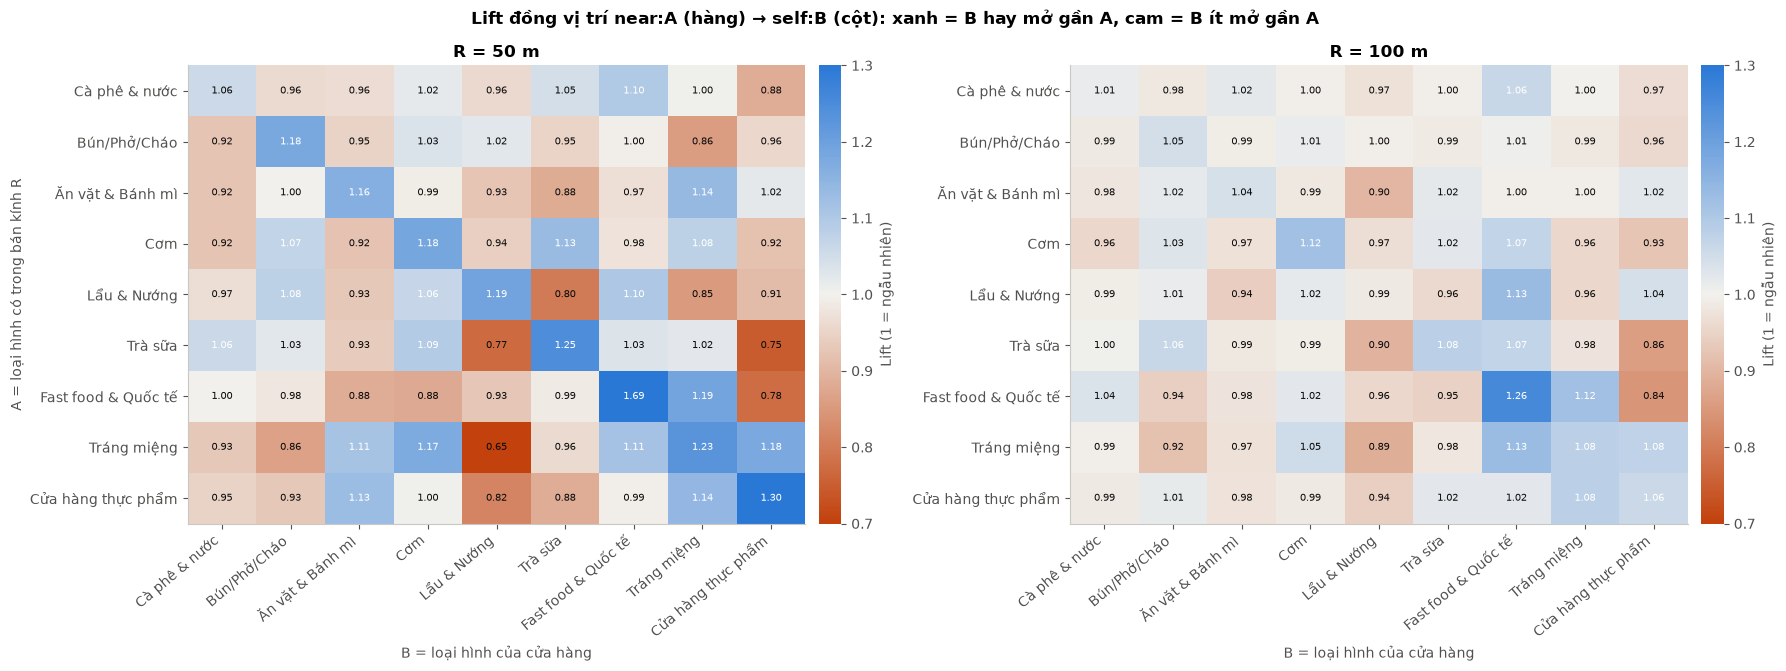

Lift đường chéo (cùng loại tụ lại gần nhau):
                     R=50 m  R=100 m
Fast food & Quốc tế    1.69     1.26
Cửa hàng thực phẩm     1.30     1.06
Trà sữa                1.25     1.08
Tráng miệng            1.23     1.08
Lẩu & Nướng            1.19     0.99
Cơm                    1.18     1.12
Bún/Phở/Cháo           1.18     1.05
Ăn vặt & Bánh mì       1.16     1.04
Cà phê & nước          1.06     1.01


In [13]:
def lift_matrix(oh):
    g = ft.GROUP_ORDER
    L = pd.DataFrame(index=g, columns=g, dtype=float)
    for a in g:
        na = oh[f"near:{a}"]
        for b in g:
            sb = oh[f"self:{b}"]
            L.loc[a, b] = sb[na].mean() / sb.mean()
    return L.astype(float)

LM = {R: lift_matrix(oh_nb[R]) for R in (50, 100)}
for R, L in LM.items():
    L.to_csv(TABLES / f"04_colocation_lift_matrix_R{R}.csv", encoding="utf-8-sig")
diverging = viz.mpl.colors.LinearSegmentedColormap.from_list("div", ["#c2410c", "#f2f1ed", viz.PALETTE[0]])
fig, axes = plt.subplots(1, 2, figsize=(18, 6.8))
for ax, R in zip(axes, (50, 100)):
    viz.heatmap(LM[R], f"R = {R} m", "B = loại hình của cửa hàng", "A = loại hình có trong bán kính R" if R == 50 else "",
                fmt=".2f", ax=ax, cmap=diverging, vmin=0.7, vmax=1.3, cbar_label="Lift (1 = ngẫu nhiên)")
fig.suptitle("Lift đồng vị trí near:A (hàng) → self:B (cột): xanh = B hay mở gần A, cam = B ít mở gần A", fontweight="bold")
fig.tight_layout(); viz.save_fig(fig, "04_colocation_lift_matrix"); plt.show()
diag = pd.DataFrame({f"R={R} m": np.diag(LM[R]) for R in (50, 100)}, index=ft.GROUP_ORDER).sort_values("R=50 m", ascending=False)
print("Lift đường chéo (cùng loại tụ lại gần nhau):")
print(diag.round(2).to_string())

In [14]:
print("Top luật near → self, R = 50 m:")
show(rules_nb50, 20)

Top luật near → self, R = 50 m:


,antecedents_str,consequents_str,support,support_count,confidence,lift,conviction
0,near:Cửa hàng thực phẩm + near:Fast food & Quốc tế,self:Fast food & Quốc tế,0.014,45,0.136,1.968,1.077
1,near:Cà phê & nước + near:Fast food & Quốc tế,self:Fast food & Quốc tế,0.029,92,0.125,1.810,1.064
2,near:Cơm + near:Fast food & Quốc tế,self:Fast food & Quốc tế,0.019,60,0.121,1.752,1.059
3,near:Cà phê & nước + near:Khác,self:Fast food & Quốc tế,0.012,39,0.118,1.710,1.055
4,near:Bún/Phở/Cháo + near:Fast food & Quốc tế,self:Fast food & Quốc tế,0.023,73,0.117,1.695,1.054
5,near:Fast food & Quốc tế,self:Fast food & Quốc tế,0.034,110,0.116,1.690,1.054
6,near:Fast food & Quốc tế + near:Lẩu & Nướng,self:Fast food & Quốc tế,0.013,43,0.109,1.584,1.045
7,near:Bún/Phở/Cháo + near:Khác,self:Fast food & Quốc tế,0.011,34,0.106,1.542,1.042
8,near:Khác,self:Fast food & Quốc tế,0.014,45,0.103,1.491,1.038
9,near:Fast food & Quốc tế + near:Ăn vặt & Bánh mì,self:Fast food & Quốc tế,0.019,60,0.103,1.491,1.038


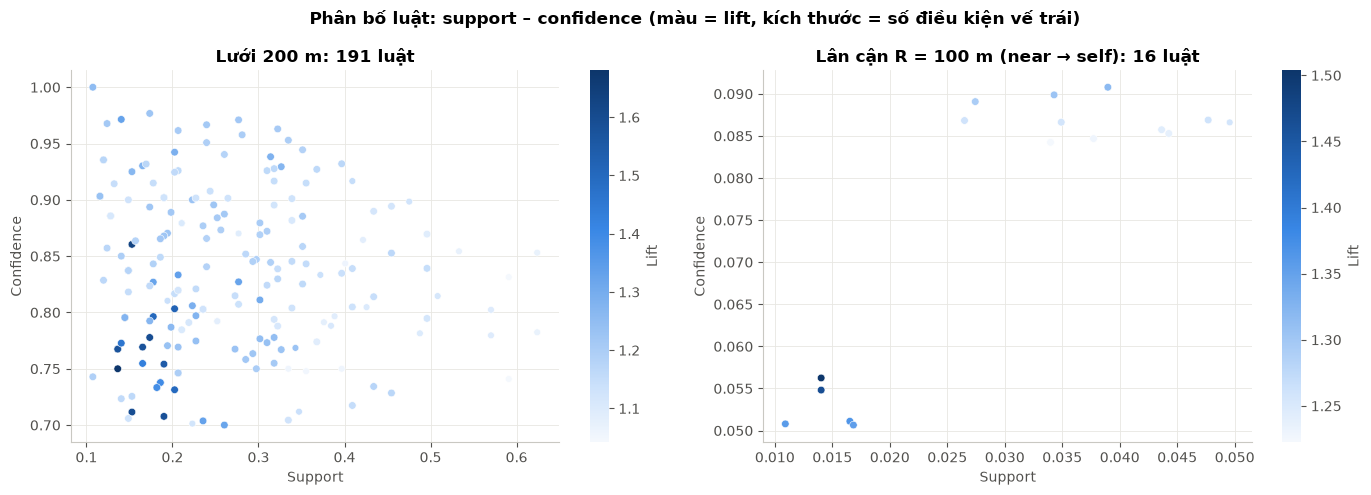

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, r, title in [(axes[0], rules_grid, "Lưới 200 m"), (axes[1], rules_nb, "Lân cận R = 100 m (near → self)")]:
    sc = ax.scatter(r["support"], r["confidence"], c=r["lift"], s=18 + 6 * r["n_antecedents"], cmap=viz.SEQ_CMAP,
                    edgecolor="white", linewidth=0.4)
    cb = plt.colorbar(sc, ax=ax); cb.set_label("Lift"); cb.outline.set_visible(False)
    ax.set_title(f"{title}: {len(r)} luật"); ax.set_xlabel("Support"); ax.set_ylabel("Confidence")
fig.suptitle("Phân bố luật: support – confidence (màu = lift, kích thước = số điều kiện vế trái)", fontweight="bold")
fig.tight_layout(); viz.save_fig(fig, "04_rules_scatter"); plt.show()

## Diễn giải các luật chính

**Về thuật toán (Apriori và FP-Growth):**
- Cả hai luôn cho **cùng số tập phổ biến**, đúng như lý thuyết vì cả hai đều chính xác.
- Trên dữ liệu nhỏ (3.208 transaction × 20 item, hoặc 242 × 10), **Apriori của mlxtend lại nhanh hơn**: khoảng 2–9 ms, so với 3–19 ms của FP-Growth.
  Lý do là Apriori trong mlxtend được vector hóa bằng numpy, còn FP-Growth dựng cây bằng Python thuần.
- Lợi thế của FP-Growth chỉ xuất hiện khi số tập phổ biến lớn. Ở dữ liệu lân cận với min_support = 0,01 (8.157 tập), FP-Growth mất 162 ms so với 211 ms của Apriori.
  Kết luận: với quy mô dữ liệu của đề tài, chọn thuật toán nào **không ảnh hưởng** tới kết quả.

**(a) Trong cửa hàng:** chỉ có 4 luật, nhưng lift rất cao.
- *Fast Food → International Food* (lift 6,2): các quán gà rán, burger được gắn nhãn kèm "quốc tế".
- *Cơm + Bún/Cháo → Lẩu & Nướng* (lift 5,4) và *Lẩu & Nướng + Cơm → Bún/Cháo* (confidence 0,81): nhóm **quán ăn gia đình / quán nhậu đa món** bán cả cơm, bún và lẩu nướng.
- Ứng dụng: quán Lẩu & Nướng mở rộng thực đơn sang cơm và bún là mô hình phổ biến.

**(b1) Lưới 200 m:** 191 luật, lift 1,2–1,7, ví dụ *Trà sữa + Tráng miệng → Fast food & Quốc tế* (lift 1,68).
- Tuy nhiên, các ô chứa vế trái đông gấp khoảng 2 lần ô trung bình (26 so với 13 cửa hàng), và số cửa hàng trong ô tương quan mạnh với số loại hình (r = 0,82).
- Vì vậy luật lưới chủ yếu nói rằng **"các loại hình ít phổ biến (tráng miệng, trà sữa, đồ quốc tế) chỉ xuất hiện cùng nhau ở khu rất đông quán"**. Đây là thông tin về mật độ, không phải về sự hút nhau giữa các loại hình.

**(b2) Lân cận: phát hiện chính.**
1. **Quán cùng loại tụ lại gần nhau** (đường chéo của ma trận > 1, rõ nhất ở R = 50 m):
   - Fast food & Quốc tế: lift 1,69 ở R = 50 m, 1,26 ở R = 100 m;
   - Cửa hàng thực phẩm: 1,30; Trà sữa: 1,25; Cơm và Bún/Phở: khoảng 1,2.

   Đây là **hiệu ứng "phố chuyên doanh"**: khách đi tìm món nào thì tới khu có nhiều quán món đó. Với Fast food, một phần nguyên nhân là các thương hiệu đặt trong cùng trung tâm thương mại hoặc khu ẩm thực.
2. **Fast food & Quốc tế và Tráng miệng hút nhau theo cả hai chiều** (lift 1,12–1,13 ở R = 100 m). Ngoài ra, Fast food hay mở gần quán Lẩu & Nướng (1,13) và quán Cơm (1,07). Đây là các loại hình hướng tới giới trẻ, dân văn phòng, thường mở gần nhau.
3. **Một số cặp né nhau** (lift < 1):
   - Cửa hàng thực phẩm ít mở gần Fast food & Quốc tế (0,84) và gần Trà sữa (0,86);
   - Lẩu & Nướng ít mở gần Trà sữa (0,90) và gần Tráng miệng (0,89).

   Các cặp này phục vụ tệp khách và khung giờ khác nhau (chợ/tạp hóa so với ăn chơi; lẩu nướng buổi tối so với trà sữa, tráng miệng).
4. **Cảnh báo luật hiển nhiên:** nhóm cà phê có mặt quanh 88% cửa hàng (R = 100 m). Vì vậy mọi luật "X → near:Cà phê & nước" đều có confidence ≥ 0,93 nhưng lift chỉ 0,97–1,09, tức **không mang thông tin**.
   Đây là lý do phải xếp hạng theo lift và conviction thay vì confidence.
5. **Nhìn chung, hiệu ứng đồng vị trí là yếu.** Lift lân cận nằm trong khoảng 0,84–1,97, so với 4–6 của luật trong cửa hàng. Hải Châu là môi trường F&B **trộn lẫn**: gần như loại hình nào cũng có ở gần loại hình nào.
   Hệ quả là việc đoán loại hình từ môi trường xung quanh (notebook 05) sẽ khó. Nếu có tín hiệu, tín hiệu đó chủ yếu đến từ **hiệu ứng tụ cùng loại**.